In [7]:
from scripts.read_field import read_dir, draw_field, animate_field
from scripts.mm.experiment import Experiment
import os 
import numpy as np 
from typing import Literal
import matplotlib.pyplot as plt

In [13]:
# path = os.path.join("./01-repulsion/skyrmion_system")
# runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[5:]
# path = os.path.join("./02-attraction/skyrmion_system")
# frame = [3,5]
# runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[frame[0]:frame[1] + 1]
path = os.path.join("./old")
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-83")])
data = [read_dir(run) for run in runs]
experiments = [Experiment.load(run) for run in runs]

In [5]:
def trajectory(data, experiment: Experiment, method: Literal['center', 'charge'] = 'center'):
    xs = np.array([])
    ys = np.array([])
    W = experiment.width / experiment.dx
    H = experiment.height / experiment.dx
    X, Y = np.meshgrid(np.arange(-W, W) * experiment.dx, -np.arange(-H, H) * experiment.dx)
    for i in range(len(data)):
        if method == 'center':
            weight = (1- data[i,:,:,2]) ** 2
        if method == 'charge':
            weight = np.sum(data[i] * np.linalg.cross(np.gradient(data[i], axis=0), np.gradient(data[i], axis=1)), axis=2)
        norm = np.sum(weight)

        x = np.sum(weight * X) / norm
        y = np.sum(weight * Y) / norm
        xs = np.append(xs, x)
        ys = np.append(ys, y)

    xs = xs - experiment.vortex_to[0]
    ys = ys - experiment.vortex_to[1]
    return xs, ys

(-7.0, 7.0)

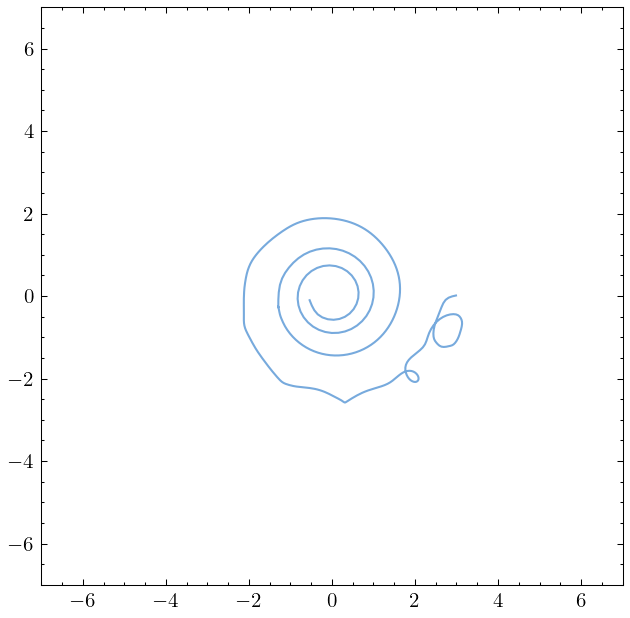

In [10]:
from scipy.interpolate import make_smoothing_spline

ts = [trajectory(d, e, method='center') for d, e in zip(data, experiments)]
xs, ys = [], []
curr = [np.float64(0), np.float64(0)]

for t in ts:
    xs = [*xs, *t[0]]
    ys = [*ys, *t[1]]
    curr[0] = xs[-1]
    curr[1] = ys[-1]

t = np.linspace(0, 1, len(xs))
t_fine = np.linspace(0, 1, len(xs) * 3)
l = 1e-11
xs, ys =  make_smoothing_spline(t,xs, lam=l)(t_fine), make_smoothing_spline(t,ys, lam=l)(t_fine)

plt.subplots(figsize=(5,5))
plt.plot(xs, ys)
plt.xlim([-7,7])
plt.ylim([-7,7])

In [5]:
xs, ys

(array([ 2.98749261,  2.89615821,  2.8110175 ,  2.73826416,  2.68184416,
         2.63637549,  2.59405671,  2.54933213,  2.50631553,  2.47172261,
         2.45095693,  2.44355991,  2.44743662,  2.46065818,  2.48206567,
         2.51072315,  2.54591472,  2.58798285,  2.63758787,  2.6944715 ,
         2.75378943,  2.80926922,  2.8558931 ,  2.89514678,  2.93061591,
         2.965209  ,  2.99818707,  3.02759017,  3.05194033,  3.07245576,
         3.09129012,  3.10989078,  3.12560417,  3.13430227,  3.13250323,
         3.12062844,  3.1005534 ,  3.07358749,  3.03748328,  2.98862066,
         2.92427311,  2.84754181,  2.76385731,  2.67845138,  2.59517136,
         2.51729161,  2.4479192 ,  2.38899935,  2.34197937,  2.30722082,
         2.27716918,  2.24075833,  2.18842416,  2.12213487,  2.04915315,
         1.97654118,  1.90955576,  1.85259601,  1.80968813,  1.78183172,
         1.76853876,  1.76911899,  1.78123716,  1.80172165,  1.82757665,
         1.85743511,  1.89078644,  1.92699713,  1.9

sh: code: command not found


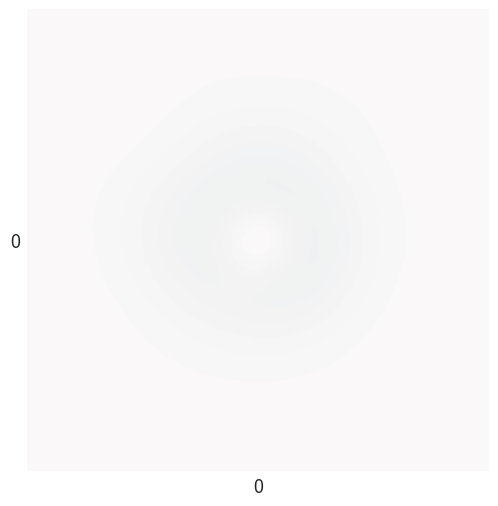

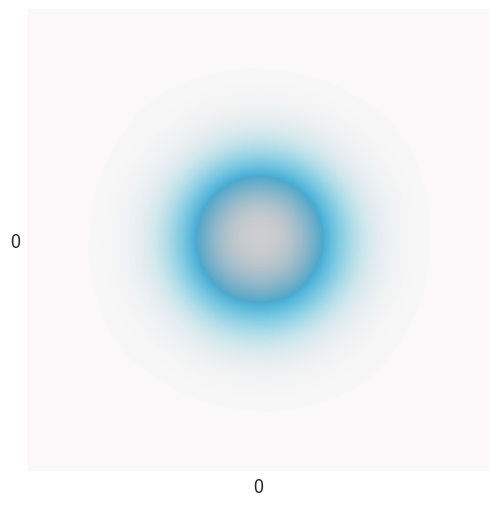

In [14]:
exp = experiments[0]
animate_field(np.concat(data), './old/drive-83', mode='spirality')

fig, ax = plt.subplots()
draw_field(ax, data[0][2], mode='spirality', cutoff=1)
# plt.imshow(data[-1][11,:,:,2], extent=([-exp.width, exp.width, -exp.height, exp.height]), vmin=-1, vmax=1)
# plt.colorbar()
# plt.plot(*ts[1])